# Neuron Migration - Rules of t2 (projected maturity value)

The offer simulates the policy month by month with the parameters of the application date. The task text leaves
open the order of the charges, the rounding, the growth formula and the age of the risk charge. They were found in
four steps:

1. The **real risk bookings** (`t3_booking.csv`) of death benefit option C, where the sum at risk is the constant
   sum insured, show the age convention and the rounding.
2. A **search over all conventions** finds the order of the charges.
3. The **rule finder** on the remaining mismatches points to the COBOL offers.
4. A test of **single data changes** shows that COBOL used a different age.

# Import libraries

In [1]:
import sys
import pathlib
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from decimal import Decimal, ROUND_DOWN, ROUND_HALF_UP
from dateutil.relativedelta import relativedelta

sys.path.insert(0, '..')
sys.path.insert(0, '../../../research')
from legacy_loader import LegacyData
from projection import offer_terms, projected_values
from risk import mortality_table
from tools.rule_finder import find_rules
import t2_search

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

# Hyperparameters

In [2]:
project_folder = pathlib.Path('../../..').resolve()

targets_dir = project_folder / 'targets'

cache_dir = project_folder / '.cache'

conversion = pd.Timestamp('2007-08-11')

cent = Decimal('0.01')

In [3]:
data = LegacyData(project_folder / 'legacy', cache_dir=cache_dir)
years = pd.read_csv(targets_dir / 't2_projection_year.csv')
target_years = years.groupby('policy_id').value.apply(lambda values: [Decimal(str(v)).quantize(cent) for v in values])

# Step 1: the risk charge in the real bookings

For death benefit option C the sum at risk is the sum insured, so the monthly risk charge depends only on the age.
Policy `BL10000013` pays 3.82 for twelve months and 4.20 from the first anniversary on: **the age is fixed at the
start of each policy year**.

In [4]:
bookings = pd.read_csv(targets_dir / 't3_booking.csv')
legacy_bookings = data.table('NRBOOK')[['BK_BOOKID', 'BK_EVTNR', 'BK_TRDDT']]
risk = bookings[bookings.booking_type == 'RSK'].merge(legacy_bookings, left_on='booking_id', right_on='BK_BOOKID')
risk = risk.groupby(['policy_id', 'BK_EVTNR']).agg(amount=('amount_pc', 'sum'), day=('BK_TRDDT', 'first'),
                                                    funds=('amount_pc', 'size')).reset_index()
risk[risk.policy_id == 'BL10000013'].head(14)

,policy_id,BK_EVTNR,amount,day,funds
634,BL10000013,3,3.82,2016-09-01,1
635,BL10000013,5,3.82,2016-10-01,1
636,BL10000013,7,3.82,2016-11-01,1
637,BL10000013,9,3.82,2016-12-01,1
638,BL10000013,11,3.82,2017-01-01,1
639,BL10000013,13,3.82,2017-02-01,1
640,BL10000013,15,3.82,2017-03-01,1
641,BL10000013,17,3.82,2017-04-01,1
642,BL10000013,19,3.82,2017-05-01,1
643,BL10000013,21,3.82,2017-06-01,1


In [5]:
terms = offer_terms(data).set_index('PH_POLNR')
mortality = mortality_table(data)
option_c = risk[risk.policy_id.isin(terms.index[terms.OPTION == 'C']) & (risk.funds == 1)].join(terms, on='policy_id')

policy_year = [relativedelta(day, begin).years for day, begin in zip(option_c.day, option_c.PH_BEGDT)]
year_start = [begin + relativedelta(years=k) for begin, k in zip(option_c.PH_BEGDT, policy_year)]
ages = {
    'last birthday': [relativedelta(start, birth).years for start, birth in zip(year_start, option_c.PS_BIRTH)],
    'nearest birthday': [relativedelta(start + relativedelta(months=6), birth).years
                         for start, birth in zip(year_start, option_c.PS_BIRTH)],
}

def risk_charge(row, age, mode):
    smoker = row.CG_SMKFAC if row.PS_SMOKE == 'J' else 1
    exact = row.RK_SUMIN * mortality[(row.CG_MORTTB, row.SEX, age)] * (1 + row.RK_LOAD) * smoker / 12
    return float(exact.quantize(cent, mode))

cobol = option_c.day < conversion
results = []
for name, age in ages.items():
    for mode in [ROUND_HALF_UP, ROUND_DOWN]:
        right = np.isclose(option_c.amount, [risk_charge(row, a, mode) for row, a in zip(option_c.itertuples(), age)])
        results.append({'age': name, 'rounding': mode, 'COBOL era': right[cobol].mean(), 'Neuron NG': right[~cobol].mean()})
pd.DataFrame(results)

,age,rounding,COBOL era,Neuron NG
0,last birthday,ROUND_HALF_UP,0.184154,0.510914
1,last birthday,ROUND_DOWN,0.400428,0.227831
2,nearest birthday,ROUND_HALF_UP,0.396146,1.000000
3,nearest birthday,ROUND_DOWN,1.000000,0.525239


Age at the **nearest birthday** at the start of the policy year. The COBOL system **truncated** the charges to the
cent, Neuron NG rounds **half up**: each matches 100 % of the bookings of its era.

# Step 2: the order of the charges

With the risk charge known, the search tries every order of admin fee, management charge and risk charge, and both
"charges, then growth" and "growth, then charges", on the first three years of 80 single-premium offers.

In [6]:
policies = t2_search.policies()
sample = policies[policies.PH_PRDCD == 'FLSP'].head(80)
base = {'pdate': 'app', 'growth': 'r12', 'round': True, 'entry_round': True, 'amc': 'pot2', 'age_at': 'year',
        'age': 'nearest6', 'era': True}

results = []
for order, sequence in itertools.product(['charges_first', 'growth_first'], itertools.permutations(['adm', 'amc', 'rsk'])):
    options = {**base, 'order': order, 'seq': sequence}
    right = sum(t2_search.project(p, options, years=3) == target_years[pid][:3] for pid, p in sample.iterrows())
    results.append({'growth': 'after charges' if order == 'charges_first' else 'before charges',
                    'charge order': ' -> '.join(sequence), 'right of 80': right})
pd.DataFrame(results).sort_values('right of 80', ascending=False)

,growth,charge order,right of 80
0,after charges,adm -> amc -> rsk,80
1,after charges,adm -> rsk -> amc,40
4,after charges,rsk -> adm -> amc,39
2,after charges,amc -> adm -> rsk,0
3,after charges,amc -> rsk -> adm,0
5,after charges,rsk -> amc -> adm,0
6,before charges,adm -> amc -> rsk,0
7,before charges,adm -> rsk -> amc,0
8,before charges,amc -> adm -> rsk,0
9,before charges,amc -> rsk -> adm,0


Only one combination reproduces all 80 offers: **admin fee -> management charge -> risk charge**, each on the value
left, **then growth** by rate / 12. The same rule matches the regular-premium products when the management charge of
the base pot is used for the whole value ("the whole value is treated as one amount").

# Step 3: the rule finder on the remaining mismatches

With these rules (and the Neuron NG age for every offer), 21 projections still differ from the first years on.

In [7]:
first_rule = {**base, 'order': 'charges_first', 'seq': ('adm', 'amc', 'rsk')}
wrong = pd.Series({pid: t2_search.project(p, first_rule) != target_years[pid] for pid, p in policies.iterrows()})

features = pd.DataFrame({
    'APPDT': policies.PH_APPDT,
    'AGE_BEGIN': [relativedelta(b + relativedelta(months=6), d).years for b, d in zip(policies.PH_BEGDT, policies.PS_BIRTH)],
    'AGE_END': [relativedelta(e + relativedelta(months=6), d).years for e, d in zip(policies.PH_ENDDT, policies.PS_BIRTH)],
    'OPTION': policies.opt, 'PRODUCT': policies.PH_PRDCD,
}, index=policies.index)
rules = find_rules(features.loc[wrong.index], wrong, min_samples_leaf=3)

21 of 3019 values wrong (0.70%)
|--- APPDT <= 2007.30
|   |--- AGE_END <= 60.50
|   |   |--- class: right
|   |--- AGE_END >  60.50
|   |   |--- AGE_BEGIN <= 62.50
|   |   |   |--- class: wrong
|   |   |--- AGE_BEGIN >  62.50
|   |   |   |--- class: right
|--- APPDT >  2007.30
|   |--- OPTION_B <= 0.50
|   |   |--- class: right
|   |--- OPTION_B >  0.50
|   |   |--- class: right



All of them are COBOL offers (applied for before the conversion in 2007).

# Step 4: what COBOL did differently

Changing one input at a time shows that every one of the 21 offers is reproduced exactly when the insured person is
**one year older**. Of several age formulas, only `round(days since birth / 365)` raises the age for exactly these
21 offers and for no other COBOL offer: dividing by 365 ignores the leap days, so the age turns over a few days early.

In [8]:
cobol_offers = policies[policies.PH_APPDT < conversion]
nearest = pd.Series([relativedelta(b + relativedelta(months=6), d).years
                     for b, d in zip(cobol_offers.PH_BEGDT, cobol_offers.PS_BIRTH)], index=cobol_offers.index)
days = (cobol_offers.PH_BEGDT - cobol_offers.PS_BIRTH).dt.days
candidates = {
    'days / 365, rounded': (days / 365 + 0.5).astype(int),
    'days / 365.25, rounded': (days / 365.25 + 0.5).astype(int),
    'months, rounded': ((cobol_offers.PH_BEGDT.dt.year * 12 + cobol_offers.PH_BEGDT.dt.month
                         - cobol_offers.PS_BIRTH.dt.year * 12 - cobol_offers.PS_BIRTH.dt.month + 6) // 12),
    'difference of the years': cobol_offers.PH_BEGDT.dt.year - cobol_offers.PS_BIRTH.dt.year,
}
mismatches = set(wrong[wrong].index)
pd.DataFrame([{'formula': name, 'offers with a different age': int((age != nearest).sum()),
               'of them the 21 mismatches': len(set(age.index[age != nearest]) & mismatches)}
              for name, age in candidates.items()])

,formula,offers with a different age,of them the 21 mismatches
0,"days / 365, rounded",21,21
1,"days / 365.25, rounded",4,3
2,"months, rounded",59,19
3,difference of the years,201,14


# Result

In [9]:
values = projected_values(data)
maturity = pd.read_csv(targets_dir / 't2_projected_maturity_value.csv')
print('yearly values exact:', sum(values[pid] == years for pid, years in target_years.items()), 'of', len(target_years))

listed = set(data.table('NREXCP').query("EX_TARGET.str.startswith('t2')", engine='python').EX_POLNR)
corrections = [(row.policy_id, row.maturity_value, float(values[row.policy_id][-1]), row.policy_id in listed)
               for row in maturity.itertuples() if Decimal(str(row.maturity_value)).quantize(cent) != values[row.policy_id][-1]]
corrections = pd.DataFrame(corrections, columns=['policy', 'target', 'calculated', 'listed in NREXCP'])
corrections['difference'] = corrections.target - corrections.calculated
corrections

yearly values exact: 3019 of 3019


,policy,target,calculated,listed in NREXCP,difference
0,BL10000128,397339.61,392484.61,True,4855.0
1,BL10001762,15718.34,14144.34,True,1574.0
2,BL10002196,270328.08,268602.08,False,1726.0
3,BL10002973,123931.68,122433.68,False,1498.0
4,BL10003323,45507.44,43560.44,True,1947.0
5,BL10003583,70122.82,71383.82,True,-1261.0
6,BL10003808,129737.45,133692.45,True,-3955.0
7,BL10004278,309249.99,305955.99,False,3294.0


Every yearly value of every offer is exact. The 8 maturity values that differ are off by whole francs while the
yearly values of the same offers are right: they were overwritten by hand (5 listed in `NREXCP`, 3 not). They are
outliers for t5.

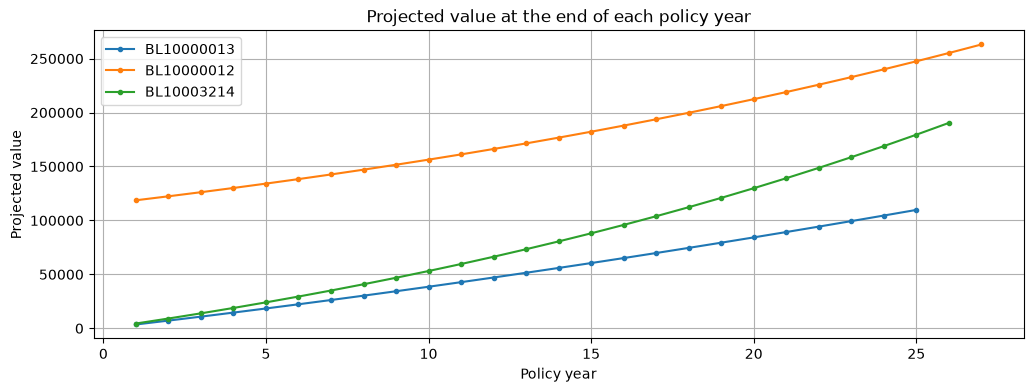

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
for pid in ['BL10000013', 'BL10000012', 'BL10003214']:
    ax.plot(range(1, len(values[pid]) + 1), [float(v) for v in values[pid]], marker='.', label=pid)
ax.set_xlabel('Policy year')
ax.set_ylabel('Projected value')
ax.set_title('Projected value at the end of each policy year')
ax.legend()
ax.grid()
plt.show()

# Summary

| Rule | Evidence |
|---|---|
| Parameters (growth rate, charges, entry charge) valid on the **application date** | convention search |
| Monthly: premium less entry charge -> admin fee -> management charge -> risk charge -> growth rate / 12 | 80 / 80 offers, only this order |
| Management charge of the **base pot** for the whole value | regular-premium offers |
| Risk charge = sum at risk x qx x (1 + loading) x smoker factor / 12, age fixed per policy year | real risk bookings |
| Neuron NG: age at the nearest birthday, rounding half up | 100 % of the bookings |
| COBOL (applied before 2007-08-11): age = round(days / 365), amounts truncated | exactly the 21 COBOL mismatches |

Train accuracy 99.735 %: 3,011 of 3,019; the 8 misses are manual corrections.